# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Ni Putu Diah Pramisara Putri
- **Email:** ds014b6x1375@student.devacademy.id
- **ID Dicoding:** DS014B6X1375

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1:** Bagaimana perubahan rata-rata konsentrasi PM2.5 setiap bulan selama periode Maret 2013 hingga Februari 2017, dan pada periode kapan konsentrasi PM2.5 mencapai tingkat tertinggi?

Keterangan:
- Specific: Berfokus pada perubahan konsentrasi PM2.5 berdasarkan bulan.
- Measurable: Menggunakan nilai rata-rata konsentrasi PM2.5 setiap bulan.
- Action-Oriented: Hasil analisis dapat membantu mengidentifikasi periode yang memerlukan perhatian lebih terhadap kualitas udara.
- Relevant: PM2.5 merupakan salah satu indikator penting dalam pemantauan pencemaran udara.
- Time-bound: Dibatasi pada periode Maret 2013 hingga Februari 2017.

**Pertanyaan 2:** Stasiun pemantauan mana yang memiliki rata-rata konsentrasi PM2.5 tertinggi dan terendah selama periode Maret 2013 hingga Februari 2017?

Keterangan:
- Specific: Berfokus pada perbandingan konsentrasi PM2.5 antarstasiun pemantauan.
- Measurable: Menggunakan nilai rata-rata PM2.5 dari setiap stasiun.
- Action-Oriented: Hasil analisis dapat membantu menentukan wilayah yang perlu diprioritaskan dalam pemantauan kualitas udara.
- Relevant: Perbedaan konsentrasi polutan antarwilayah dapat menjadi informasi penting dalam evaluasi kualitas udara.
- Time-bound: Menggunakan data periode Maret 2013 hingga Februari 2017.

**Pertanyaan 3:** Bagaimana hubungan antara faktor meteorologi, seperti suhu (TEMP), tekanan udara (PRES), titik embun (DEWP), curah hujan (RAIN), dan kecepatan angin (WSPM), dengan konsentrasi PM2.5 selama periode Maret 2013 hingga Februari 2017?

Keterangan:
- Specific: Berfokus pada hubungan antara faktor meteorologi dan konsentrasi PM2.5.
- Measurable: Menggunakan nilai korelasi antarvariabel.
- Action-Oriented: Hasil analisis dapat membantu memahami kondisi meteorologi yang berkaitan dengan perubahan konsentrasi PM2.5.
- Relevant: Kondisi meteorologi merupakan faktor yang relevan untuk dipelajari dalam analisis kualitas udara.
- Time-bound: Dibatasi pada periode Maret 2013 hingga Februari 2017.

## Import Semua Packages/Library yang Digunakan

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
import glob

from google.colab import files

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

## Data Wrangling
Tahap data wrangling dilakukan untuk mempersiapkan dataset agar memiliki struktur dan kualitas yang sesuai untuk proses analisis. Proses ini mencakup pemeriksaan missing values, pengecekan data duplikat, penyesuaian tipe data, serta pengolahan variabel yang diperlukan. Selain itu, dilakukan penyesuaian data berdasarkan kebutuhan analisis PM2.5 agar informasi yang digunakan lebih terstruktur, konsisten, dan dapat menghasilkan analisis yang lebih akurat.

### Gathering Data

Pada tahap ini dilakukan proses pengumpulan dan pemuatan data menggunakan Air Quality Dataset. Dataset terdiri dari 12 file CSV yang masing-masing merepresentasikan satu stasiun pemantauan kualitas udara di Beijing, Tiongkok.

Setiap file berisi data pengukuran kualitas udara dan kondisi meteorologi yang dicatat setiap jam selama periode 1 Maret 2013 hingga 28 Februari 2017.

Seluruh file CSV akan digabungkan menjadi satu DataFrame agar proses analisis dapat dilakukan secara menyeluruh, baik berdasarkan waktu maupun lokasi stasiun pemantauan.

#### Load Dataset Air Quality

In [39]:
# Menentukan lokasi folder dataset
data_path = 'data/'

# Mengambil seluruh file CSV dari folder data
all_files = glob.glob(os.path.join(data_path, '*.csv'))

# Membaca dan menggabungkan seluruh file CSV
df_list = []

for file in all_files:
    data = pd.read_csv(file)
    df_list.append(data)

df = pd.concat(df_list, ignore_index=True)

# Menampilkan informasi dataset
print("Jumlah file CSV:", len(all_files))
print("Ukuran dataset:", df.shape)

df.head()

Jumlah file CSV: 12
Ukuran dataset: (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,5.0,14.0,4.0,12.0,200.0,85.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Nongzhanguan
1,2,2013,3,1,1,8.0,12.0,6.0,14.0,200.0,84.0,-0.7,1025.1,-22.1,0.0,NW,3.9,Nongzhanguan
2,3,2013,3,1,2,3.0,6.0,5.0,14.0,200.0,83.0,-1.2,1025.3,-24.6,0.0,NNW,5.3,Nongzhanguan
3,4,2013,3,1,3,5.0,5.0,5.0,14.0,200.0,84.0,-1.4,1026.2,-25.5,0.0,N,4.9,Nongzhanguan
4,5,2013,3,1,4,5.0,5.0,6.0,21.0,200.0,77.0,-1.9,1027.1,-24.5,0.0,NNW,3.2,Nongzhanguan


**Insight:**
- Dataset terdiri dari 12 file CSV yang merepresentasikan 12 stasiun pemantauan kualitas udara di Beijing. Setiap file memiliki 35.064 baris data dengan total keseluruhan sebanyak 420.768 baris.

- Data mencakup periode Maret 2013 hingga Februari 2017 dengan pencatatan setiap jam. Dataset memuat informasi konsentrasi enam jenis polutan udara serta kondisi meteorologi yang dapat digunakan untuk menganalisis pola kualitas udara berdasarkan waktu dan lokasi.

### Assessing Data

Tahap assessing data dilakukan untuk mengevaluasi kualitas dataset sebelum proses pembersihan. Pemeriksaan dilakukan dengan mengidentifikasi missing values, data duplikat, tipe data, serta kemungkinan nilai pengukuran yang tidak sesuai.

Pemeriksaan ini bertujuan untuk mengetahui permasalahan yang dapat memengaruhi hasil analisis sehingga tindakan pembersihan dapat dilakukan berdasarkan kondisi data yang ditemukan.

#### Identifying Data problem

Pada tahap ini dilakukan identifikasi terhadap berbagai permasalahan yang terdapat dalam Air Quality Dataset. Pemeriksaan dilakukan untuk mengetahui kondisi data secara keseluruhan, mulai dari kelengkapan data, kesesuaian tipe data, keberadaan data duplikat, hingga kemungkinan adanya nilai pengukuran yang tidak wajar. Hasil pemeriksaan ini akan menjadi dasar dalam menentukan langkah pembersihan data pada tahap selanjutnya.

In [40]:
print("Informasi Dataset:")
df.info()

print("\nJumlah dan Persentase Missing Values:")

missing_values = pd.DataFrame({
    'Jumlah Missing Values': df.isnull().sum(),
    'Persentase (%)': (df.isnull().sum() / len(df) * 100).round(2)
})

display(
    missing_values[missing_values['Jumlah Missing Values'] > 0]
    .sort_values(by='Jumlah Missing Values', ascending=False)
)

print("\nJumlah Data Duplikat:", df.duplicated().sum())

pollutant_columns = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']

print("\nPemeriksaan Nilai Negatif:")
for col in pollutant_columns:
    print(f"{col}: {(df[col] < 0).sum()}")

print("\nPemeriksaan Data Waktu:")
print("Tahun paling awal:", df['year'].min())
print("Tahun paling akhir:", df['year'].max())
print("Bulan paling awal:", df['month'].min())
print("Bulan paling akhir:", df['month'].max())

print("\nPemeriksaan Stasiun:")
print("Jumlah stasiun:", df['station'].nunique())
print("Nama stasiun:", df['station'].unique())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

Jumlah dan Persentase Mis

,Jumlah Missing Values,Persentase (%)
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09



Jumlah Data Duplikat: 0

Pemeriksaan Nilai Negatif:
PM2.5: 0
PM10: 0
SO2: 0
NO2: 0
CO: 0
O3: 0

Pemeriksaan Data Waktu:
Tahun paling awal: 2013
Tahun paling akhir: 2017
Bulan paling awal: 1
Bulan paling akhir: 12

Pemeriksaan Stasiun:
Jumlah stasiun: 12
Nama stasiun: ['Nongzhanguan' 'Dingling' 'Huairou' 'Aotizhongxin' 'Wanliu' 'Gucheng'
 'Changping' 'Tiantan' 'Guanyuan' 'Shunyi' 'Dongsi' 'Wanshouxigong']


**Steps to Take:**
- Memeriksa struktur dataset, jumlah baris dan kolom, serta tipe data pada setiap kolom.
- Mengidentifikasi jumlah dan persentase missing values untuk mengetahui kelengkapan data.
- Memeriksa keberadaan data duplikat pada seluruh baris dataset.
- Memeriksa kemungkinan nilai negatif pada kolom konsentrasi polutan, yaitu PM2.5, PM10, SO2, NO2, CO, dan O3.
- Memeriksa rentang tahun dan bulan pengamatan serta jumlah stasiun pemantauan yang terdapat dalam dataset.

**Insight:**
- Dataset terdiri dari 420.768 baris dan 18 kolom dengan tipe data yang sesuai, yaitu 5 kolom bertipe integer, 11 kolom bertipe float, dan 2 kolom bertipe object. Data mencakup periode tahun 2013 hingga 2017 dan berasal dari 12 stasiun pemantauan kualitas udara di Beijing.
- Ditemukan missing values pada 12 kolom dengan jumlah terbanyak pada CO sebanyak 20.701 data (4,92%), O3 sebanyak 13.277 data (3,16%), dan NO2 sebanyak 12.116 data (2,88%). Tidak ditemukan data duplikat maupun nilai negatif pada seluruh kolom konsentrasi polutan.

### Cleaning Data

Tahap cleaning data dilakukan untuk memperbaiki kualitas dataset berdasarkan permasalahan yang telah ditemukan pada tahap assessing data. Proses pembersihan difokuskan pada penanganan missing values agar data dapat digunakan secara optimal dalam proses analisis. Penanganan dilakukan dengan mempertimbangkan jenis data, karakteristik pengukuran, serta stasiun pemantauan sehingga informasi penting dalam dataset tetap dapat dipertahankan.

#### Fixing missing value problem

Pada tahap ini dilakukan penanganan terhadap missing values yang ditemukan pada dataset. Proses pembersihan dilakukan dengan mempertimbangkan karakteristik data pengukuran kualitas udara yang dicatat setiap jam. Untuk kolom numerik, nilai kosong akan ditangani menggunakan interpolasi berdasarkan urutan waktu dalam masing-masing stasiun, kemudian menggunakan median stasiun untuk mengisi nilai kosong yang masih tersisa. Sementara itu, missing values pada kolom arah angin (wd) akan diisi menggunakan modus dari masing-masing stasiun.

In [41]:
df = df.sort_values(
    ['station', 'year', 'month', 'day', 'hour']
).reset_index(drop=True)

numeric_columns = [
    'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3',
    'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'
]

missing_before = df.isnull().sum().sum()

for col in numeric_columns:
    df[col] = df.groupby('station')[col].transform(
        lambda x: x.interpolate(
            method='linear',
            limit=3,
            limit_area='inside'
        )
    )

for col in numeric_columns:
    df[col] = df[col].fillna(
        df.groupby('station')[col].transform('median')
    )

station_modes = df.groupby('station')['wd'].agg(
    lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
)

df['wd'] = df['wd'].fillna(
    df['station'].map(station_modes)
)

if df['wd'].isnull().sum() > 0:
    df['wd'] = df['wd'].fillna(df['wd'].mode()[0])

missing_after = df.isnull().sum().sum()

print("Missing values sebelum cleaning:", missing_before)
print("Missing values setelah cleaning:", missing_after)

print("\nMissing Values Setiap Kolom:")
display(df.isnull().sum().to_frame('Missing Values'))

print("\nUkuran Dataset Setelah Cleaning:", df.shape)

Missing values sebelum cleaning: 74027
Missing values setelah cleaning: 0

Missing Values Setiap Kolom:


,Missing Values
No,0
year,0
month,0
day,0
hour,0
PM2.5,0
PM10,0
SO2,0
NO2,0
CO,0



Ukuran Dataset Setelah Cleaning: (420768, 18)


**Insight:**
- Sebelum proses cleaning, ditemukan sebanyak 74.027 missing values pada dataset. Setelah dilakukan penanganan menggunakan interpolasi, median berdasarkan stasiun, dan modus berdasarkan stasiun, seluruh missing values berhasil ditangani sehingga tidak terdapat nilai kosong pada dataset.
- Proses cleaning tidak mengurangi jumlah data. Dataset tetap memiliki 420.768 baris dan 18 kolom, sehingga seluruh data pengamatan dari 12 stasiun pemantauan tetap dipertahankan untuk tahap analisis selanjutnya.


## Exploratory Data Analysis (EDA)

Tahap Exploratory Data Analysis (EDA) dilakukan untuk memahami karakteristik dan kondisi awal dataset sebelum memasuki proses analisis lebih lanjut. Eksplorasi mencakup pemeriksaan struktur data, tipe data, jumlah baris dan kolom, statistik deskriptif, serta distribusi nilai pada setiap variabel. Tahap ini juga bertujuan untuk mengidentifikasi pola awal, nilai yang tidak wajar, dan permasalahan dalam dataset yang dapat memengaruhi hasil analisis.

### Explore Data Distribution

Pada tahap ini dilakukan eksplorasi terhadap distribusi konsentrasi polutan untuk memahami karakteristik data secara statistik. Eksplorasi dilakukan dengan melihat nilai rata-rata, standar deviasi, nilai minimum, maksimum, serta distribusi masing-masing polutan. Hasilnya digunakan untuk mengetahui variasi konsentrasi polutan yang tercatat selama periode pengamatan.

,count,mean,std,min,25%,50%,75%,max
PM2.5,420768.0,79.55,80.57,2.00,21.0,55.0,110.0,999.0
PM10,420768.0,104.61,92.08,2.00,36.0,82.0,145.0,999.0
SO2,420768.0,15.76,21.64,0.29,3.0,7.0,19.0,500.0
NO2,420768.0,50.43,34.93,1.03,23.0,43.0,70.8,290.0
CO,420768.0,1221.12,1150.49,100.00,500.0,900.0,1500.0,10000.0
O3,420768.0,56.95,56.24,0.21,11.0,44.0,81.0,1071.0


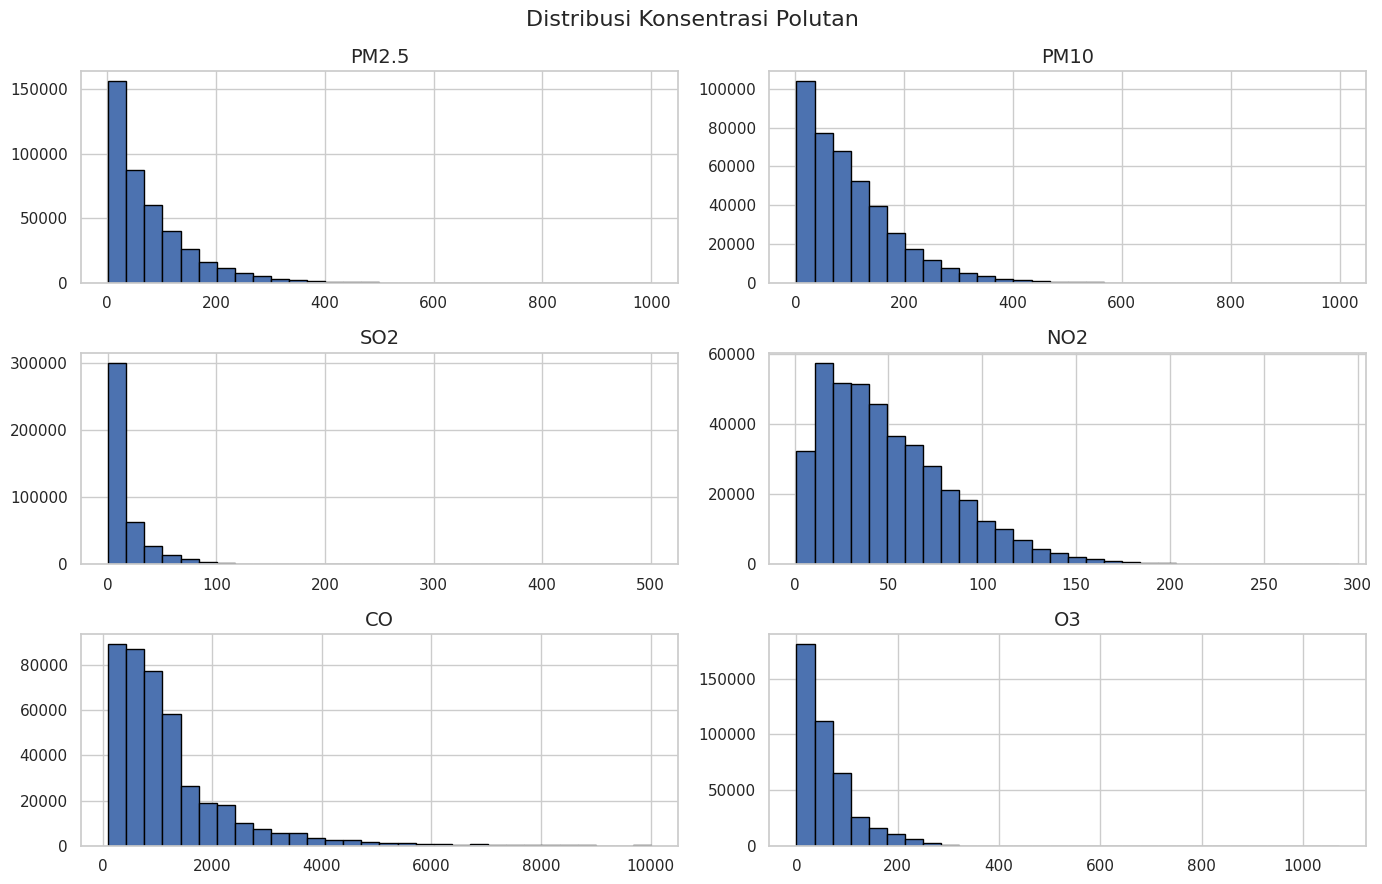

In [42]:
pollutant_columns = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']

display(df[pollutant_columns].describe().T.round(2))

df[pollutant_columns].hist(
    figsize=(14, 9),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribusi Konsentrasi Polutan', fontsize=16)
plt.tight_layout()
plt.show()

**Insight:**
- Konsentrasi PM10 memiliki rata-rata tertinggi sebesar 104,61, diikuti PM2.5 sebesar 79,55, O3 sebesar 56,95, NO2 sebesar 50,43, SO2 sebesar 15,76, dan CO sebesar 1.221,12. Berdasarkan nilai rata-rata dan median, konsentrasi beberapa polutan menunjukkan distribusi yang cenderung menceng ke kanan (right-skewed), terutama PM2.5, PM10, dan CO.
- Seluruh polutan memiliki nilai maksimum yang jauh lebih tinggi dibandingkan nilai mediannya. Sebagai contoh, PM2.5 mencapai 999, PM10 mencapai 999, dan CO mencapai 10.000. Hal ini menunjukkan adanya nilai pengukuran ekstrem yang perlu diperhatikan dalam analisis lebih lanjut karena dapat memengaruhi hasil statistik dan interpretasi distribusi data.

### Explore Monthly PM2.5 Trends

Eksplorasi ini dilakukan untuk mengetahui perubahan rata-rata konsentrasi PM2.5 berdasarkan bulan selama periode Maret 2013 hingga Februari 2017. Pengelompokan data berdasarkan tahun dan bulan digunakan untuk mengidentifikasi pola temporal serta mengetahui periode dengan konsentrasi PM2.5 tertinggi dan terendah.

In [43]:
monthly_pm25 = (
    df.groupby(['year', 'month'])['PM2.5']
    .mean()
    .reset_index()
)

monthly_pm25['periode'] = (
    monthly_pm25['year'].astype(str) + '-' +
    monthly_pm25['month'].astype(str).str.zfill(2)
)

display(monthly_pm25[['periode', 'PM2.5']].round(2))

highest_month = monthly_pm25.loc[monthly_pm25['PM2.5'].idxmax()]
lowest_month = monthly_pm25.loc[monthly_pm25['PM2.5'].idxmin()]

print("PM2.5 tertinggi:")
print(highest_month[['periode', 'PM2.5']])

print("\nPM2.5 terendah:")
print(lowest_month[['periode', 'PM2.5']])

,periode,PM2.5
0,2013-03,104.64
1,2013-04,62.23
2,2013-05,80.85
3,2013-06,101.29
4,2013-07,67.40
5,2013-08,60.64
6,2013-09,76.12
7,2013-10,91.58
8,2013-11,73.82
9,2013-12,78.26


PM2.5 tertinggi:
periode       2015-12
PM2.5      149.518756
Name: 33, dtype: object

PM2.5 terendah:
periode      2016-02
PM2.5      42.836267
Name: 35, dtype: object


**Insight:**

- Rata-rata konsentrasi PM2.5 menunjukkan perubahan yang cukup fluktuatif selama periode Maret 2013 hingga Februari 2017. Konsentrasi tertinggi tercatat pada Desember 2015 sebesar 149,52, sedangkan konsentrasi terendah terjadi pada Februari 2016 sebesar 42,84.
- Secara umum, konsentrasi PM2.5 cenderung mengalami peningkatan pada beberapa bulan menjelang akhir tahun, terutama pada November dan Desember. Sementara itu, konsentrasi yang lebih rendah beberapa kali terlihat pada periode pertengahan tahun, meskipun pola tersebut tidak terjadi secara konsisten setiap tahun.

### Explore PM2.5 by Monitoring Station

Eksplorasi ini bertujuan untuk membandingkan rata-rata konsentrasi PM2.5 pada 12 stasiun pemantauan kualitas udara di Beijing. Perbandingan dilakukan untuk mengetahui perbedaan kondisi kualitas udara berdasarkan lokasi serta mengidentifikasi stasiun dengan rata-rata konsentrasi PM2.5 tertinggi dan terendah.

In [44]:
station_pm25 = (
    df.groupby('station')['PM2.5']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

station_pm25.columns = ['Stasiun', 'Rata-rata PM2.5']

display(station_pm25.round(2))

print("Stasiun dengan PM2.5 tertinggi:")
display(station_pm25.head(1).round(2))

print("Stasiun dengan PM2.5 terendah:")
display(station_pm25.tail(1).round(2))

,Stasiun,Rata-rata PM2.5
0,Dongsi,85.82
1,Nongzhanguan,84.89
2,Wanshouxigong,84.71
3,Gucheng,83.69
4,Wanliu,83.30
5,Guanyuan,82.75
6,Aotizhongxin,82.37
7,Tiantan,81.90
8,Shunyi,79.28
9,Changping,70.84


Stasiun dengan PM2.5 tertinggi:


,Stasiun,Rata-rata PM2.5
0,Dongsi,85.82


Stasiun dengan PM2.5 terendah:


,Stasiun,Rata-rata PM2.5
11,Dingling,65.84


**Insight:**

- Rata-rata konsentrasi PM2.5 menunjukkan adanya perbedaan antarstasiun pemantauan. Stasiun Dongsi memiliki rata-rata konsentrasi tertinggi sebesar 85,82, sedangkan stasiun Dingling memiliki rata-rata terendah sebesar 65,84 selama periode pengamatan.
- Stasiun Dongsi, Nongzhanguan, dan Wanshouxigong termasuk tiga stasiun dengan rata-rata PM2.5 tertinggi. Sementara itu, Dingling, Huairou, dan Changping memiliki rata-rata yang relatif lebih rendah dibandingkan stasiun lainnya. Hal ini menunjukkan bahwa konsentrasi PM2.5 bervariasi berdasarkan lokasi pemantauan, dengan selisih sebesar 19,98 antara stasiun dengan rata-rata tertinggi dan terendah.

### Explore Correlation between PM2.5 and Meteorological Factors

Eksplorasi ini dilakukan untuk mengetahui hubungan antara konsentrasi PM2.5 dengan faktor meteorologi, yaitu suhu (TEMP), tekanan udara (PRES), titik embun (DEWP), curah hujan (RAIN), dan kecepatan angin (WSPM). Analisis korelasi digunakan untuk melihat arah dan kekuatan hubungan antara masing-masing faktor meteorologi dengan konsentrasi PM2.5.

,PM2.5,TEMP,PRES,DEWP,RAIN,WSPM
PM2.5,1.000,-0.131,0.020,0.113,-0.014,-0.271
TEMP,-0.131,1.000,-0.813,0.820,0.038,0.033
PRES,0.020,-0.813,1.000,-0.750,-0.061,0.065
DEWP,0.113,0.820,-0.750,1.000,0.086,-0.297
RAIN,-0.014,0.038,-0.061,0.086,1.000,0.021
WSPM,-0.271,0.033,0.065,-0.297,0.021,1.000


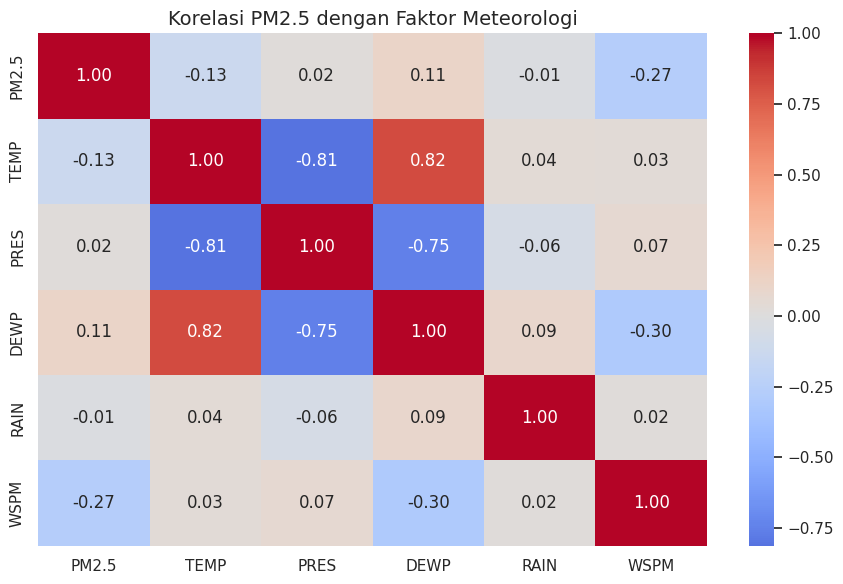

In [45]:
meteorological_columns = [
    'PM2.5', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'
]

correlation = df[meteorological_columns].corr()

display(correlation.round(3))

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Korelasi PM2.5 dengan Faktor Meteorologi')
plt.tight_layout()
plt.show()

**Insight:**

- Berdasarkan hasil korelasi, faktor meteorologi yang memiliki hubungan negatif paling kuat dengan PM2.5 adalah kecepatan angin (WSPM) dengan nilai korelasi -0,271. Hal ini menunjukkan bahwa peningkatan kecepatan angin cenderung berkaitan dengan penurunan konsentrasi PM2.5. Sementara itu, suhu (TEMP) memiliki korelasi negatif yang relatif lemah sebesar -0,131, sedangkan titik embun (DEWP) memiliki korelasi positif yang lemah sebesar 0,113.

- Tekanan udara (PRES) dan curah hujan (RAIN) memiliki hubungan yang sangat lemah dengan PM2.5, masing-masing sebesar 0,020 dan -0,014. Dengan demikian, berdasarkan data ini, kecepatan angin menunjukkan hubungan linear paling kuat dengan konsentrasi PM2.5 dibandingkan faktor meteorologi lainnya.

## Visualization & Explanatory Analysis

Tahap visualization dan explanatory analysis dilakukan untuk menyajikan hasil pengolahan data ke dalam bentuk visualisasi agar pola dan hubungan antarvariabel lebih mudah dipahami. Visualisasi yang digunakan meliputi line chart untuk menggambarkan perubahan rata-rata konsentrasi PM2.5 setiap bulan, bar chart untuk membandingkan rata-rata konsentrasi PM2.5 berdasarkan stasiun pemantauan, serta correlation heatmap untuk menunjukkan hubungan antara PM2.5 dengan faktor meteorologi. Melalui visualisasi tersebut, analisis difokuskan pada perubahan konsentrasi PM2.5 berdasarkan waktu, perbedaan konsentrasi antarstasiun, serta hubungan antara kondisi meteorologi dengan konsentrasi PM2.5.

### Pertanyaan 1: Bagaimana perubahan rata-rata konsentrasi PM2.5 setiap bulan selama periode Maret 2013 hingga Februari 2017, dan pada periode kapan konsentrasi PM2.5 mencapai tingkat tertinggi dan terendah?

Analisis ini dilakukan untuk mengetahui perubahan rata-rata konsentrasi PM2.5 setiap bulan selama periode pengamatan. Data dikelompokkan berdasarkan tahun dan bulan agar perubahan konsentrasi dapat diamati secara berurutan. Visualisasi menggunakan line chart untuk memperlihatkan pola kenaikan dan penurunan konsentrasi PM2.5 serta mengidentifikasi periode dengan konsentrasi tertinggi dan terendah.

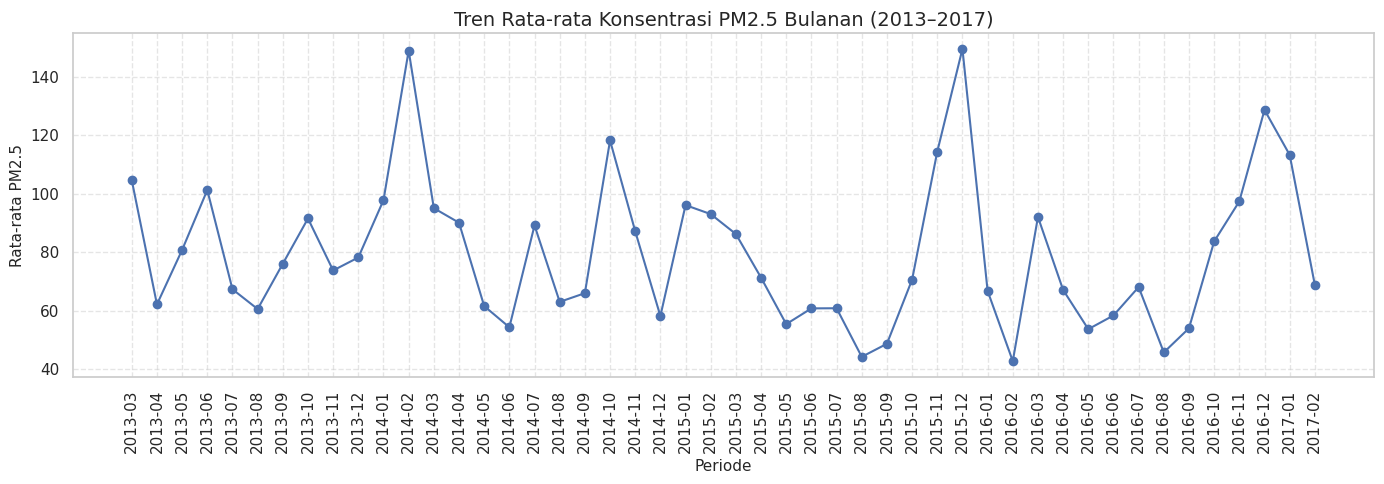

In [46]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_pm25['periode'],
    monthly_pm25['PM2.5'],
    marker='o',
    linewidth=1.5
)

plt.title('Tren Rata-rata Konsentrasi PM2.5 Bulanan (2013–2017)')
plt.xlabel('Periode')
plt.ylabel('Rata-rata PM2.5')
plt.xticks(rotation=90)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Insight:**

- Rata-rata konsentrasi PM2.5 tertinggi terjadi pada Desember 2015, yaitu sebesar 149,52.
- Konsentrasi PM2.5 terendah terjadi pada Februari 2016, yaitu sebesar 42,84.
- Terdapat selisih sebesar 106,68 antara periode dengan konsentrasi tertinggi dan terendah.
- Hasil tersebut menunjukkan bahwa konsentrasi PM2.5 mengalami perubahan yang cukup fluktuatif selama periode Maret 2013 hingga Februari 2017.
- Tingginya konsentrasi PM2.5 pada Desember 2015 menunjukkan bahwa periode tersebut perlu mendapatkan perhatian lebih dalam pemantauan kualitas udara.

### Pertanyaan 2: Stasiun pemantauan mana yang memiliki rata-rata konsentrasi PM2.5 tertinggi dan terendah selama periode Maret 2013 hingga Februari 2017?

Analisis ini dilakukan untuk membandingkan rata-rata konsentrasi PM2.5 pada setiap stasiun pemantauan kualitas udara di Beijing. Data dikelompokkan berdasarkan nama stasiun untuk mengetahui perbedaan konsentrasi PM2.5 antarwilayah. Visualisasi menggunakan bar chart agar perbandingan antarstasiun dapat terlihat dengan jelas serta memudahkan identifikasi stasiun dengan rata-rata konsentrasi tertinggi dan terendah.

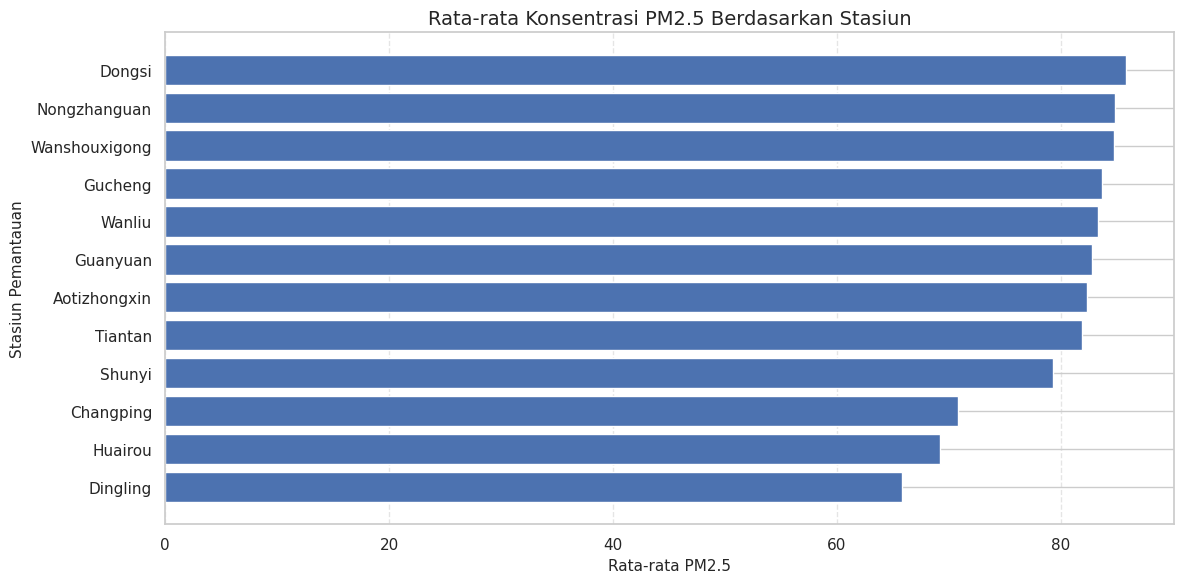

In [47]:
plt.figure(figsize=(12, 6))

plt.barh(
    station_pm25['Stasiun'],
    station_pm25['Rata-rata PM2.5']
)

plt.title('Rata-rata Konsentrasi PM2.5 Berdasarkan Stasiun')
plt.xlabel('Rata-rata PM2.5')
plt.ylabel('Stasiun Pemantauan')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Insight:**

- Stasiun Dongsi memiliki rata-rata konsentrasi PM2.5 tertinggi, yaitu sebesar 85,82.
- Stasiun Dingling memiliki rata-rata konsentrasi PM2.5 terendah, yaitu sebesar 65,84.
- Terdapat selisih sebesar 19,98 antara stasiun dengan rata-rata konsentrasi PM2.5 tertinggi dan terendah.
- Hasil ini menunjukkan bahwa konsentrasi PM2.5 memiliki variasi berdasarkan lokasi pemantauan.
- Perbedaan tersebut mengindikasikan bahwa stasiun Dongsi perlu mendapatkan perhatian lebih dalam pemantauan kualitas udara dibandingkan stasiun dengan rata-rata konsentrasi yang lebih rendah.

### Pertanyaan 3: Bagaimana hubungan antara faktor meteorologi, seperti suhu, tekanan udara, titik embun, curah hujan, dan kecepatan angin, dengan konsentrasi PM2.5 selama periode Maret 2013 hingga Februari 2017?

Analisis ini dilakukan untuk mengetahui hubungan antara konsentrasi PM2.5 dengan berbagai faktor meteorologi. Pengukuran dilakukan menggunakan metode korelasi untuk melihat arah dan kekuatan hubungan antara PM2.5 dengan suhu (TEMP), tekanan udara (PRES), titik embun (DEWP), curah hujan (RAIN), dan kecepatan angin (WSPM). Hasil analisis divisualisasikan menggunakan correlation heatmap agar hubungan antarvariabel dapat dibandingkan dengan lebih mudah.

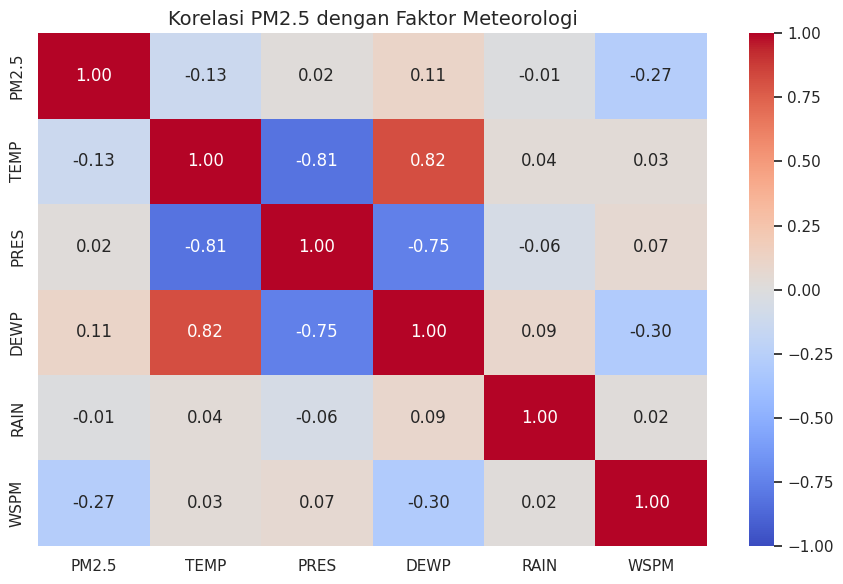

In [48]:
meteorological_columns = [
    'PM2.5', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'
]

correlation = df[meteorological_columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Korelasi PM2.5 dengan Faktor Meteorologi')
plt.tight_layout()
plt.show()

**Insight:**

- Kecepatan angin (WSPM) memiliki hubungan negatif paling kuat dengan PM2.5, dengan nilai korelasi sebesar -0,271. Hal ini menunjukkan bahwa peningkatan kecepatan angin cenderung berkaitan dengan penurunan konsentrasi PM2.5.
- Suhu (TEMP) memiliki korelasi negatif sebesar -0,131, yang menunjukkan hubungan negatif dengan kekuatan lemah.
- Titik embun (DEWP) memiliki korelasi positif sebesar 0,113, yang menunjukkan hubungan positif dengan kekuatan lemah.
- Tekanan udara (PRES) memiliki korelasi positif sebesar 0,020, sedangkan curah hujan (RAIN) memiliki korelasi negatif sebesar -0,014. Keduanya menunjukkan hubungan linear yang sangat lemah dengan PM2.5.
- Secara keseluruhan, kecepatan angin merupakan faktor meteorologi yang memiliki hubungan linear paling kuat dengan konsentrasi PM2.5 dibandingkan variabel meteorologi lainnya.

## Analisis Lanjutan

Tahap analisis lanjutan dilakukan untuk menggali informasi yang lebih mendalam mengenai pola konsentrasi PM2.5 berdasarkan faktor waktu dan kondisi lingkungan. Analisis ini difokuskan pada perbandingan konsentrasi PM2.5 berdasarkan musim, sehingga dapat diketahui apakah terdapat perbedaan tingkat pencemaran udara pada setiap musim. Hasil analisis diharapkan dapat memberikan pemahaman tambahan mengenai pola perubahan kualitas udara sepanjang tahun.

### Pertanyaan: Bagaimana perbedaan rata-rata konsentrasi PM2.5 pada empat musim (semi, panas, gugur, dan dingin), serta musim apa yang memiliki tingkat pencemaran udara tertinggi dan terendah?

Analisis ini dilakukan dengan mengelompokkan data konsentrasi PM2.5 berdasarkan empat musim, yaitu musim semi, musim panas, musim gugur, dan musim dingin. Selanjutnya, dihitung rata-rata konsentrasi PM2.5 pada masing-masing musim untuk mengetahui perbedaan tingkat pencemaran udara. Melalui analisis ini, dapat diketahui musim dengan rata-rata konsentrasi PM2.5 tertinggi dan terendah, sehingga memberikan gambaran mengenai pola perubahan kualitas udara berdasarkan kondisi musim selama periode pengamatan.

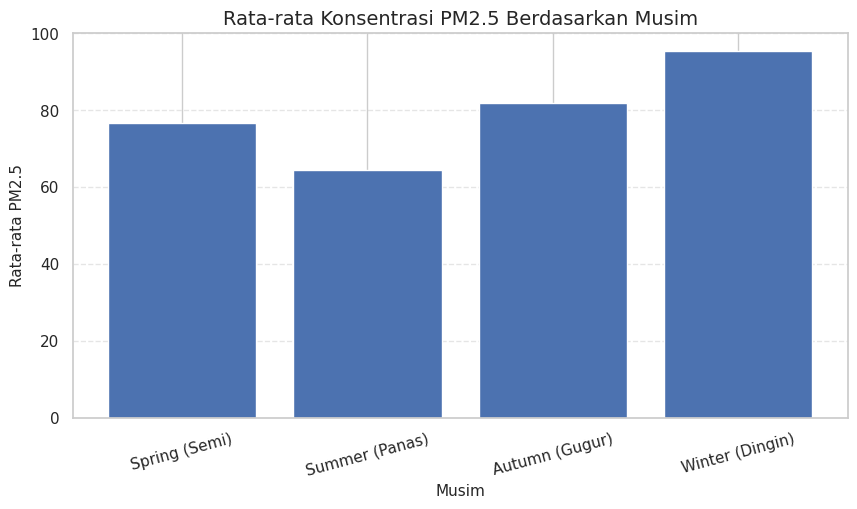

In [49]:
def tentukan_musim(bulan):
    if bulan in [3, 4, 5]:
        return 'Spring (Semi)'
    elif bulan in [6, 7, 8]:
        return 'Summer (Panas)'
    elif bulan in [9, 10, 11]:
        return 'Autumn (Gugur)'
    else:
        return 'Winter (Dingin)'

df['season'] = df['month'].apply(tentukan_musim)

rata_musim = df.groupby('season')['PM2.5'].mean()

urutan_musim = [
    'Spring (Semi)',
    'Summer (Panas)',
    'Autumn (Gugur)',
    'Winter (Dingin)'
]

rata_musim = rata_musim.reindex(urutan_musim)

plt.figure(figsize=(10, 5))

plt.bar(rata_musim.index, rata_musim.values)

plt.title('Rata-rata Konsentrasi PM2.5 Berdasarkan Musim')
plt.xlabel('Musim')
plt.ylabel('Rata-rata PM2.5')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

**Insight:**
- Musim dingin (Winter) memiliki rata-rata konsentrasi PM2.5 tertinggi sebesar 95,30, menunjukkan bahwa periode musim dingin merupakan periode dengan tingkat pencemaran partikel paling tinggi dalam dataset.
- Musim panas (Summer) memiliki rata-rata PM2.5 terendah sebesar 64,50, sehingga menjadi musim dengan kualitas udara relatif lebih baik berdasarkan indikator PM2.5.
- Musim gugur (Autumn) memiliki rata-rata sebesar 81,95, lebih tinggi dibandingkan musim semi (Spring) yang sebesar 76,77.
- Terdapat selisih sebesar 30,80 antara musim dingin dan musim panas. Konsentrasi PM2.5 pada musim dingin sekitar 47,7% lebih tinggi dibandingkan musim panas.
- Pola tersebut menunjukkan adanya perbedaan rata-rata konsentrasi PM2.5 pada setiap musim. Musim dingin memiliki konsentrasi tertinggi, sedangkan musim panas memiliki konsentrasi terendah. Perbedaan ini menunjukkan bahwa pola konsentrasi PM2.5 bervariasi berdasarkan musim selama periode pengamatan.


## Menyimpan Dataset untuk Dashboard
Setelah seluruh tahapan pembersihan dan analisis data selesai dilakukan, dataset disimpan ke dalam format CSV untuk digunakan pada tahap pembuatan dashboard. Penyimpanan ini bertujuan agar data yang telah melalui proses cleaning dan dilengkapi dengan kolom musim (season) dapat digunakan kembali tanpa perlu mengulangi proses pengolahan dari awal. Dataset disimpan dengan nama main_data.csv dan akan digunakan sebagai sumber data utama dalam membangun visualisasi interaktif menggunakan Streamlit.

In [50]:
# Menyimpan dataset yang sudah dibersihkan
df.to_csv('main_data.csv', index=False)

print("Dataset berhasil disimpan!")
print("Ukuran dataset:", df.shape)

Dataset berhasil disimpan!
Ukuran dataset: (420768, 19)


## Conclusion & Recommendation

Tahap conclusion dan recommendation dilakukan untuk merangkum hasil analisis yang telah diperoleh dari setiap tahapan sebelumnya. Kesimpulan disusun berdasarkan pola, tren, serta hubungan antarvariabel yang ditemukan dalam dataset PM2.5. Selain itu, rekomendasi diberikan sebagai bentuk tindak lanjut dari hasil analisis, sehingga informasi yang diperoleh dapat digunakan sebagai bahan pertimbangan dalam upaya pemantauan dan pengendalian pencemaran udara.

- **Conclusion Pertanyaan 1:** Berdasarkan hasil analisis bulanan, konsentrasi PM2.5 mengalami perubahan yang fluktuatif selama periode Maret 2013 hingga Februari 2017. Konsentrasi tertinggi terjadi pada Desember 2015 sebesar 149,52, sedangkan konsentrasi terendah terjadi pada Februari 2016 sebesar 42,84. Hal ini menunjukkan adanya perubahan tingkat pencemaran udara yang cukup signifikan antarperiode pengamatan.

- **Conclusion Pertanyaan 2:** Hasil perbandingan antarstasiun menunjukkan bahwa Dongsi memiliki rata-rata konsentrasi PM2.5 tertinggi sebesar 85,82, sedangkan Dingling memiliki rata-rata terendah sebesar 65,84. Perbedaan ini menunjukkan bahwa tingkat konsentrasi PM2.5 tidak merata pada seluruh lokasi pemantauan.

- **Conclusion Pertanyaan 3:** Hasil analisis korelasi menunjukkan bahwa kecepatan angin (WSPM) memiliki hubungan linear paling kuat dengan PM2.5, yaitu sebesar -0,271. Sementara itu, suhu, titik embun, tekanan udara, dan curah hujan memiliki hubungan yang relatif lemah. Dengan demikian, kecepatan angin merupakan faktor meteorologi yang memiliki hubungan linear paling kuat dengan konsentrasi PM2.5 dibandingkan variabel meteorologi lainnya. Namun, nilai korelasi tersebut masih menunjukkan hubungan yang relatif lemah dan tidak dapat diartikan sebagai hubungan sebab-akibat.

- **Conclusion analisis lanjutan:** Hasil analisis musiman menunjukkan bahwa musim dingin (Winter) memiliki rata-rata PM2.5 tertinggi sebesar 95,30, sedangkan musim panas (Summer) memiliki rata-rata terendah sebesar 64,50. Selisih keduanya mencapai 30,80. Hal ini menunjukkan adanya variasi konsentrasi polutan berdasarkan musim, dengan musim dingin menjadi periode yang perlu mendapat perhatian lebih dalam pemantauan kualitas udara.



**Rekomendasi Action Item:**
Berdasarkan hasil analisis konsentrasi PM2.5 di Beijing selama periode Maret 2013 hingga Februari 2017, terdapat beberapa rekomendasi tindakan yang dapat dilakukan untuk mendukung pemantauan dan pengendalian kualitas udara.

- **Meningkatkan pemantauan pada periode dengan konsentrasi PM2.5 tinggi.** Hasil analisis menunjukkan bahwa konsentrasi PM2.5 tertinggi terjadi pada Desember 2015, dengan rata-rata sebesar 149,52. Oleh karena itu, pemantauan kualitas udara perlu ditingkatkan pada periode ketika konsentrasi PM2.5 menunjukkan peningkatan. Data bulanan dapat dimanfaatkan untuk mengidentifikasi perubahan konsentrasi dan menentukan periode yang memerlukan perhatian lebih.

- **Memprioritaskan pengawasan pada stasiun dengan konsentrasi PM2.5 tertinggi.** Hasil perbandingan antarstasiun menunjukkan bahwa Dongsi memiliki rata-rata konsentrasi PM2.5 tertinggi sebesar 85,82, sedangkan Dingling memiliki rata-rata terendah sebesar 65,84. Dengan demikian, pengawasan kualitas udara di sekitar Stasiun Dongsi perlu lebih diprioritaskan. Evaluasi terhadap kemungkinan sumber pencemaran di wilayah tersebut juga dapat dilakukan untuk mendukung upaya pengendalian kualitas udara.

- **Mempertimbangkan faktor meteorologi dalam pemantauan kualitas udara.** Hasil analisis korelasi menunjukkan bahwa kecepatan angin (WSPM) memiliki hubungan negatif paling besar dengan konsentrasi PM2.5, yaitu sebesar -0,271. Hal ini menunjukkan kecenderungan bahwa peningkatan kecepatan angin berkaitan dengan penurunan konsentrasi PM2.5. Oleh karena itu, data kecepatan angin dan faktor meteorologi lainnya dapat digunakan sebagai informasi pendukung dalam pemantauan kualitas udara. Namun, hubungan yang ditemukan relatif lemah sehingga faktor meteorologi tidak dapat dijadikan satu-satunya dasar dalam menentukan perubahan konsentrasi PM2.5.

- **Meningkatkan kewaspadaan terhadap perubahan konsentrasi PM2.5 berdasarkan musim.** Hasil analisis lanjutan menunjukkan bahwa musim dingin memiliki rata-rata konsentrasi PM2.5 tertinggi sebesar 95,30, sedangkan musim panas memiliki rata-rata terendah sebesar 64,50. Oleh karena itu, pemantauan kualitas udara perlu lebih diperhatikan selama musim dingin karena konsentrasi PM2.5 cenderung lebih tinggi dibandingkan musim lainnya. Informasi perbedaan konsentrasi berdasarkan musim juga dapat digunakan sebagai bahan pertimbangan dalam menyusun strategi pengendalian pencemaran udara yang disesuaikan dengan kondisi setiap musim.

Secara keseluruhan, rekomendasi tindakan difokuskan pada peningkatan pemantauan berdasarkan perubahan konsentrasi PM2.5 bulanan dan musiman, pemberian perhatian lebih pada stasiun dengan rata-rata konsentrasi tertinggi, serta pemanfaatan informasi meteorologi sebagai faktor pendukung pemantauan kualitas udara. Hasil analisis ini diharapkan dapat membantu menentukan prioritas pengawasan dan mendukung upaya pengendalian pencemaran udara di Beijing.
